# Etapa 3. Regresión logística múltiple
**Reto clima: vegetación y contaminación (SIMA, Monterrey)**

Modelo de dependencia: probabilidad de que la concentración **mensual** de un contaminante (PM10, PM2.5, NO2) sea *alta* en función de la vegetación (NDVI, cobertura verde) y la meteorología.

Estructura (misma numeración que el reporte, sección 5):
0. Configuración · 1. Datos · 2. Variable respuesta · 3. Preparación · 4. Multicolinealidad
5. Especificación y resultados del modelo · 6. Validación de supuestos · 7. Eficiencia y errores · 8. Variables más importantes

# Configuración

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

# --- Parámetros que se pueden cambiar ---
RUTA = "../Exploracion_descriptiva/tablas/base_analitica_mensual.csv"
RADIO = 2000                          # radio (m) de NDVI y cobertura verde: 300, 500, 1000 o 2000 
CONTAMINANTES = ["PM10", "PM2.5", "NO2"]
PERCENTIL = 50                       # "alto" = por encima de este percentil de cada contaminante

# Carga de datos

In [31]:
base = pd.read_csv(RUTA)
print(base.shape)
base[["estacion", "fecha_mes", "temporada", "PM10", "PM2.5", "NO2", "TOUT", "RH", "RAINF", "WSR",
      f"ndvi_{RADIO}", f"verde_{RADIO}"]].head()

(360, 39)


,estacion,fecha_mes,temporada,PM10,PM2.5,NO2,TOUT,RH,RAINF,WSR,ndvi_2000,verde_2000
0,CE,2024-01,seca,80.480,31.496,24.347,14.340,55.343,0.000,6.074,0.160,4.946
1,CE,2024-02,seca,73.252,NaN,22.755,19.624,45.762,0.000,6.972,0.157,4.946
2,CE,2024-03,seca,66.381,22.894,17.515,21.376,51.811,0.000,7.559,0.180,4.946
3,CE,2024-04,seca,68.032,NaN,14.553,24.401,50.329,0.000,8.114,0.166,4.946
4,CE,2024-05,húmeda,78.591,NaN,12.759,29.792,52.475,0.920,9.780,0.136,4.946


# Variable respuesta binaria
Para cada contaminante: `y = 1` si el promedio mensual de la estación-mes supera el percentil `PERCENTIL` (por defecto la mediana) de ese contaminante, `y = 0` si no.
Con la mediana las clases quedan balanceadas. Si el equipo prefiere un umbral normativo (NOM), se puede reemplazar `umbrales` por valores fijos.

In [32]:
# Umbral por contaminante (percentil sobre los meses válidos)
umbrales = {c: base[c].quantile(PERCENTIL / 100) for c in CONTAMINANTES}
# Ejemplo de umbral fijo: umbrales = {"PM10": 70, "PM2.5": 41, "NO2": 21}

resumen_y = []
for c in CONTAMINANTES:
    validos = base[c].dropna()
    resumen_y.append({"contaminante": c, "umbral": umbrales[c], "n_validos": len(validos),
                      "n_alto (y=1)": int((validos > umbrales[c]).sum()),
                      "% alto": 100 * (validos > umbrales[c]).mean()})
pd.DataFrame(resumen_y)

,contaminante,umbral,n_validos,n_alto (y=1),% alto
0,PM10,54.113,353,176,49.858
1,PM2.5,19.243,220,110,50.000
2,NO2,13.660,326,163,50.000


# Preparación de los datos
- Predictores: NDVI y cobertura verde (radio elegido), temperatura, humedad, lluvia, viento y temporada húmeda (controla la estacionalidad).
- La lluvia es muy asimétrica → se usa `log(1 + lluvia)`.
- Las variables continuas se **estandarizan** (z-score): los coeficientes quedan comparables y los odds ratio se leen "por cada 1 desviación estándar".
- Se trabaja con casos completos (se eliminan filas con faltantes en y o en algún predictor).

In [33]:
base["RAINF_log"] = np.log1p(base["RAINF"])
base["humeda"] = (base["temporada"] == "húmeda").astype(int)

CONT = [f"ndvi_{RADIO}", f"verde_{RADIO}", "TOUT", "RH", "RAINF_log", "WSR"]   # continuas

def preparar(cont):
    """Devuelve (y, X estandarizada, datos completos) para un contaminante."""
    d = base.dropna(subset=[cont] + CONT).copy()
    d["y"] = (d[cont] > umbrales[cont]).astype(int)
    X = d[CONT].copy()
    X = (X - X.mean()) / X.std()                     # z-score
    X["humeda"] = d["humeda"]
    return d["y"], sm.add_constant(X), d

datos = {c: preparar(c) for c in CONTAMINANTES}
pd.DataFrame({c: {"n usado": len(datos[c][0]), "% y=1": 100 * datos[c][0].mean(),
                  "n estaciones": datos[c][2]["estacion"].nunique()} for c in CONTAMINANTES}).T

,n usado,% y=1,n estaciones
PM10,285.000,50.175,15.000
PM2.5,163.000,53.374,11.000
NO2,265.000,50.943,15.000


# Multicolinealidad (VIF)
VIF > 5 (o > 10) indica predictores muy correlacionados entre sí. Ojo: `verde` y `construido` son casi espejo, por eso solo se usa `verde`.

In [34]:
vif = {}
for c in CONTAMINANTES:
    X = datos[c][1]
    vif[c] = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
pd.DataFrame(vif).drop(index="const")

,PM10,PM2.5,NO2
ndvi_2000,2.947,5.604,2.907
verde_2000,2.934,4.976,2.919
TOUT,3.715,3.196,3.688
RH,2.177,1.932,2.087
RAINF_log,1.618,1.386,1.580
WSR,1.471,1.501,1.446
humeda,4.135,4.075,4.051


# Especificación y resultados del modelo
Modelo logit: $\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$, con $p = P(y=1)$.
- Se ajusta por máxima verosimilitud (`statsmodels.Logit`).
- Errores estándar **agrupados por estación** (las mediciones de una misma estación no son independientes).
- Se reporta el odds ratio: $OR = e^{\beta}$ (por 1 DE en las continuas). $OR>1$ sube la probabilidad de nivel alto; $OR<1$ la baja.

In [35]:
modelos = {}
tablas = {}
for c in CONTAMINANTES:
    y, X, d = datos[c]
    m = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d["estacion"]})
    modelos[c] = m
    ic = np.exp(m.conf_int())
    tablas[c] = pd.DataFrame({"coef": m.params, "OR": np.exp(m.params), "IC95_inf": ic[0], "IC95_sup": ic[1],
                              "p": m.pvalues})
    print(f"\n{c} n={int(m.nobs)} | pseudo-R² McFadden={m.prsquared:.3f} | AIC={m.aic:.1f}")
    display(tablas[c])


PM10 n=285 | pseudo-R² McFadden=0.245 | AIC=314.4


,coef,OR,IC95_inf,IC95_sup,p
const,0.698,2.011,0.996,4.057,0.051
ndvi_2000,0.641,1.898,0.898,4.012,0.093
verde_2000,-0.818,0.441,0.248,0.784,0.005
TOUT,-0.258,0.773,0.397,1.503,0.447
RH,-0.539,0.583,0.304,1.118,0.104
RAINF_log,-0.242,0.785,0.496,1.241,0.300
WSR,0.112,1.118,0.649,1.927,0.687
humeda,-1.477,0.228,0.083,0.625,0.004



PM2.5 n=163 | pseudo-R² McFadden=0.230 | AIC=189.5


,coef,OR,IC95_inf,IC95_sup,p
const,1.332,3.787,1.513,9.479,0.004
ndvi_2000,-0.998,0.369,0.133,1.018,0.054
verde_2000,0.082,1.085,0.507,2.322,0.833
TOUT,0.421,1.523,0.885,2.623,0.129
RH,0.562,1.755,0.982,3.136,0.058
RAINF_log,-0.402,0.669,0.406,1.103,0.115
WSR,-0.103,0.902,0.472,1.724,0.755
humeda,-2.625,0.072,0.015,0.341,0.001



NO2 n=265 | pseudo-R² McFadden=0.358 | AIC=251.6


,coef,OR,IC95_inf,IC95_sup,p
const,-0.138,0.871,0.339,2.239,0.774
ndvi_2000,0.084,1.087,0.458,2.579,0.849
verde_2000,-1.012,0.363,0.152,0.870,0.023
TOUT,-1.683,0.186,0.060,0.578,0.004
RH,-0.877,0.416,0.206,0.839,0.014
RAINF_log,0.189,1.208,0.654,2.232,0.546
WSR,-0.440,0.644,0.266,1.559,0.329
humeda,0.545,1.724,0.385,7.727,0.477


# Validación de supuestos

### Linealidad del logit
Cada predictor continuo debe tener relación lineal con el logit de $p$. Se divide el predictor en 5 grupos (cuantiles) y se grafica el logit de la proporción de `y=1` contra el promedio del predictor; los puntos deberían seguir aproximadamente una recta.

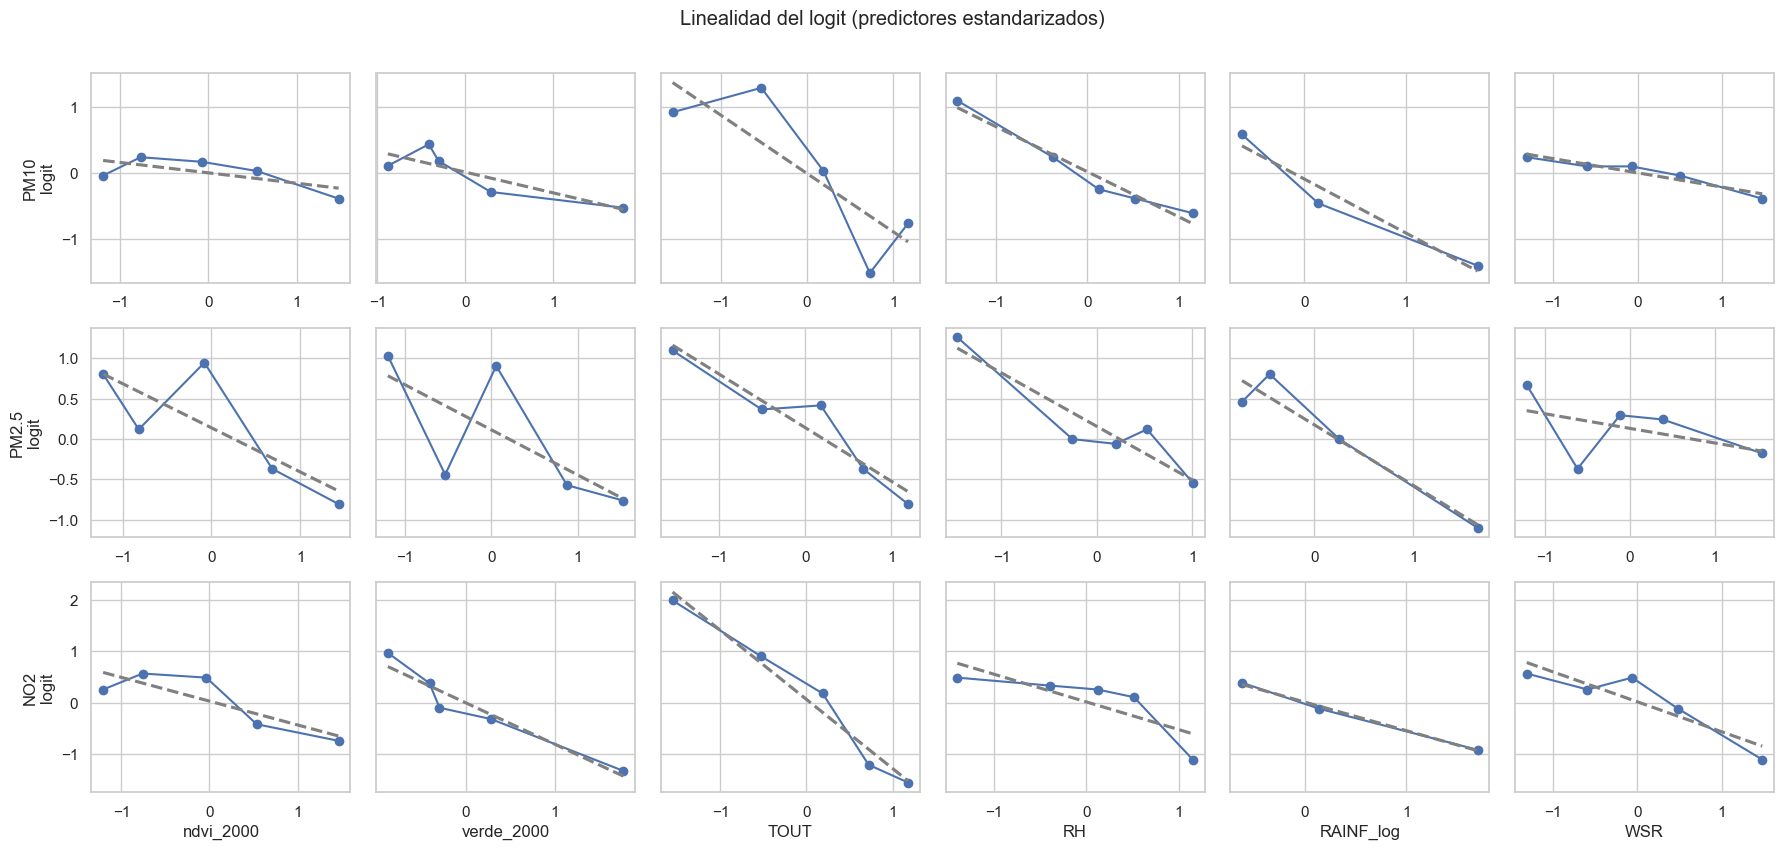

In [36]:
def logit_emp(y, x, bins=5):
    g = pd.DataFrame({"x": x, "y": y})
    g["b"] = pd.qcut(g["x"], bins, duplicates="drop")
    t = g.groupby("b", observed=True).agg(x=("x", "mean"), s=("y", "sum"), n=("y", "size"))
    t["logit"] = np.log((t.s + 0.5) / (t.n - t.s + 0.5))          # +0.5 evita logit infinito
    return t

fig, axes = plt.subplots(len(CONTAMINANTES), len(CONT), figsize=(3 * len(CONT), 2.8 * len(CONTAMINANTES)), sharey="row")
for i, c in enumerate(CONTAMINANTES):
    y, X, d = datos[c]
    for j, v in enumerate(CONT):
        t = logit_emp(y, X[v])
        ax = axes[i, j]
        ax.plot(t.x, t.logit, "o-")
        sns.regplot(x=t.x, y=t.logit, scatter=False, ci=None, color="gray", line_kws={"ls": "--"}, ax=ax)
        ax.set_xlabel(v if i == len(CONTAMINANTES) - 1 else "")
        ax.set_ylabel(f"{c}\nlogit" if j == 0 else "")
plt.suptitle("Linealidad del logit (predictores estandarizados)", y=1.01)
plt.tight_layout(); plt.show()

### Observaciones influyentes
Distancia de Cook: mide cuánto cambiaría el modelo al quitar una observación. Referencia usual: $4/n$.

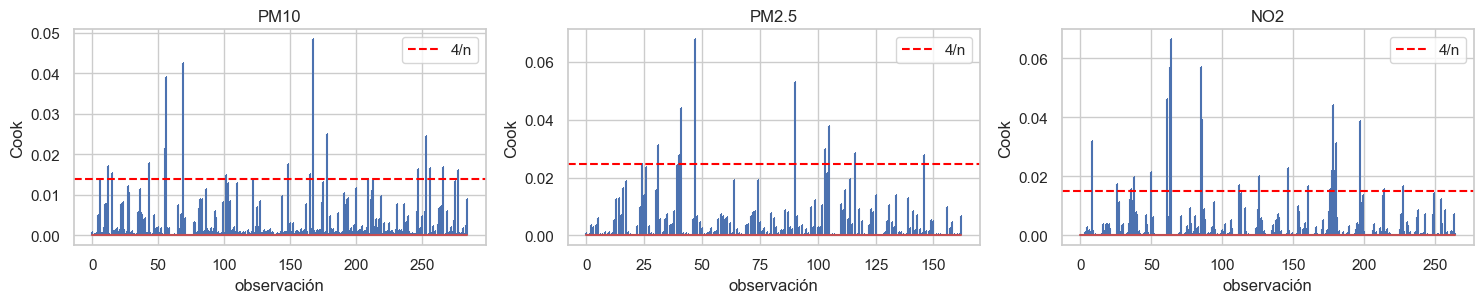

Top 5 influyentes PM10


,estacion,fecha_mes,PM10,cook
220,SE,2024-05,74.340,0.048
86,NE3,2025-03,75.764,0.043
73,NE3,2024-02,54.359,0.039
231,SE,2025-04,49.604,0.025
324,SO2,2025-01,53.982,0.024


Top 5 influyentes PM2.5


,estacion,fecha_mes,PM2.5,cook
197,NTE2,2024-06,19.408,0.068
249,SE2,2024-10,21.440,0.053
171,NTE,2024-04,16.871,0.044
268,SE3,2024-05,31.281,0.038
132,NO2,2025-01,9.114,0.031


Top 5 influyentes NO2


,estacion,fecha_mes,NO2,cook
86,NE3,2025-03,15.557,0.066
120,NO2,2024-01,6.211,0.057
85,NE3,2025-02,16.773,0.057
83,NE3,2024-12,15.022,0.046
252,SE2,2025-01,5.926,0.044


In [37]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.2))
influyentes = {}
for ax, c in zip(axes, CONTAMINANTES):
    y, X, d = datos[c]
    glm = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    cook = pd.Series(glm.get_influence().cooks_distance[0], index=d.index)
    ax.stem(range(len(cook)), cook.values, markerfmt=",")
    ax.axhline(4 / len(cook), color="red", ls="--", label="4/n")
    ax.set_title(c); ax.set_xlabel("observación"); ax.set_ylabel("Cook"); ax.legend()
    influyentes[c] = d.loc[cook.nlargest(5).index, ["estacion", "fecha_mes", c]].assign(cook=cook.nlargest(5))
plt.tight_layout(); plt.show()
for c in CONTAMINANTES:
    print(f"Top 5 influyentes {c}"); display(influyentes[c])

### Bondad de ajuste
- **Prueba de razón de verosimilitud** (modelo completo vs. solo constante).
- **Hosmer-Lemeshow**: compara casos observados vs. esperados en 10 grupos de probabilidad. $H_0$: el modelo ajusta bien (p alto = bien).
- **McFadden R²**: valores de 0.2–0.4 ya se consideran buen ajuste en logística.

In [38]:
def hosmer_lemeshow(y, p, g=10):
    t = pd.DataFrame({"y": y.values, "p": p.values})
    t["grupo"] = pd.qcut(t["p"], g, duplicates="drop")
    r = t.groupby("grupo", observed=True).agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "size"))
    chi2 = (((r.obs - r.esp) ** 2) / (r.esp * (1 - r.esp / r.n))).sum()
    gl = len(r) - 2
    return chi2, gl, 1 - stats.chi2.cdf(chi2, gl)

gof = []
for c in CONTAMINANTES:
    y, X, d = datos[c]
    m_ml = sm.Logit(y, X).fit(disp=0)                  # ajuste sin cluster solo para LR / HL
    hl, gl, p_hl = hosmer_lemeshow(y, m_ml.predict(X))
    gof.append({"contaminante": c, "McFadden R2": m_ml.prsquared, "LR chi2": m_ml.llr,
                "p (LR)": m_ml.llr_pvalue, "HL chi2": hl, "HL gl": gl, "p (HL)": p_hl})
pd.DataFrame(gof).set_index("contaminante")

,McFadden R2,LR chi2,p (LR),HL chi2,HL gl,p (HL)
contaminante,,,,,,
PM10,0.245,96.672,0.000,14.234,8,0.076
PM2.5,0.230,51.758,0.000,11.562,8,0.172
NO2,0.358,131.650,0.000,8.839,8,0.356


### Independencia de las observaciones
Una estación aporta hasta 24 meses, así que las observaciones no son del todo independientes. Se revisa si los residuos de Pearson tienen sesgo por estación; si lo hay, justifica los errores agrupados (ya usados en la sección 5).

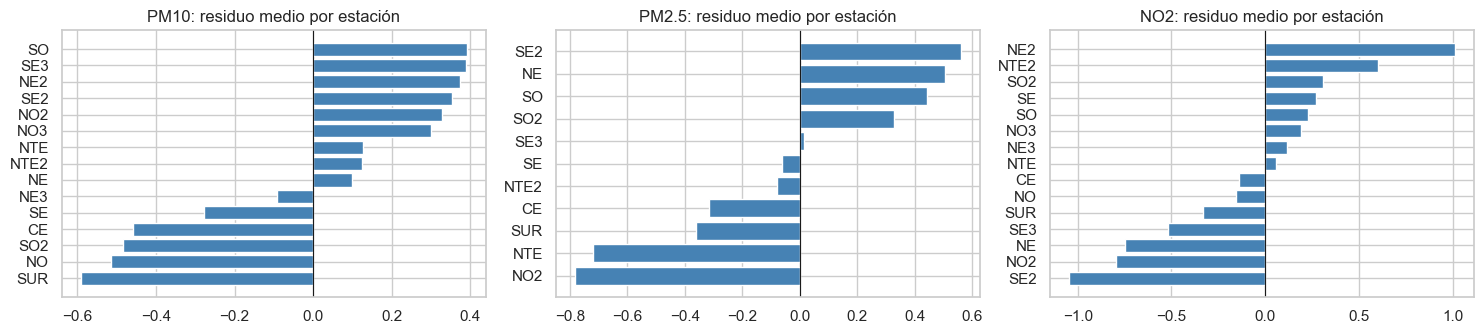

In [39]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.5), sharex=False)
for ax, c in zip(axes, CONTAMINANTES):
    y, X, d = datos[c]
    p = modelos[c].predict(X)
    res = ((y - p) / np.sqrt(p * (1 - p))).groupby(d["estacion"]).mean().sort_values()
    ax.barh(res.index, res.values, color="steelblue")
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{c}: residuo medio por estación")
plt.tight_layout(); plt.show()

# Eficiencia del modelo y análisis de errores
Validación cruzada **por estación** (`GroupKFold`): el modelo se entrena con unas estaciones y se prueba en estaciones que nunca vio. Es una prueba más exigente que un split al azar, porque mide si el modelo generaliza a sitios nuevos. Umbral de clasificación: 0.5.

In [40]:
metricas, cv_pred = [], {}
for c in CONTAMINANTES:
    y, X, d = datos[c]
    Xc = X.drop(columns="const")
    n_folds = min(5, d["estacion"].nunique())
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    proba = cross_val_predict(pipe, Xc, y, groups=d["estacion"], cv=GroupKFold(n_folds), method="predict_proba")[:, 1]
    pred = (proba >= 0.5).astype(int)
    cv_pred[c] = pd.DataFrame({"y": y, "proba": proba, "pred": pred, "estacion": d["estacion"], "fecha_mes": d["fecha_mes"]})
    metricas.append({"contaminante": c, "exactitud": accuracy_score(y, pred), "AUC": roc_auc_score(y, proba),
                     "precisión": precision_score(y, pred), "sensibilidad": recall_score(y, pred),
                     "F1": f1_score(y, pred), "línea base": max(y.mean(), 1 - y.mean())})
pd.DataFrame(metricas).set_index("contaminante")

,exactitud,AUC,precisión,sensibilidad,F1,línea base
contaminante,,,,,,
PM10,0.705,0.703,0.698,0.727,0.712,0.502
PM2.5,0.656,0.693,0.667,0.713,0.689,0.534
NO2,0.766,0.801,0.797,0.726,0.760,0.509


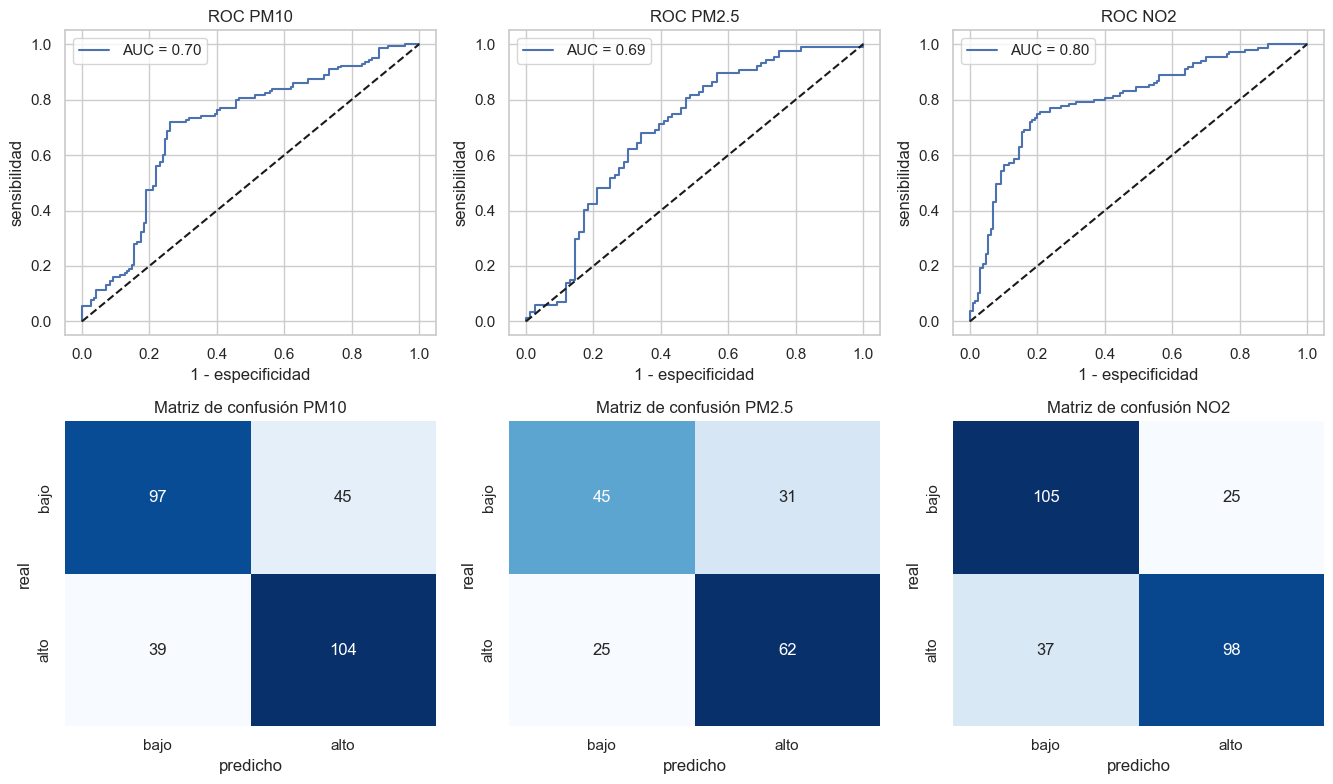

In [41]:
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(4.5 * len(CONTAMINANTES), 8))
for j, c in enumerate(CONTAMINANTES):
    r = cv_pred[c]
    fpr, tpr, _ = roc_curve(r.y, r.proba)
    axes[0, j].plot(fpr, tpr, label=f"AUC = {roc_auc_score(r.y, r.proba):.2f}")
    axes[0, j].plot([0, 1], [0, 1], "k--"); axes[0, j].set_title(f"ROC {c}")
    axes[0, j].set_xlabel("1 - especificidad"); axes[0, j].set_ylabel("sensibilidad"); axes[0, j].legend()
    sns.heatmap(confusion_matrix(r.y, r.pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, j],
                xticklabels=["bajo", "alto"], yticklabels=["bajo", "alto"])
    axes[1, j].set_title(f"Matriz de confusión {c}"); axes[1, j].set_xlabel("predicho"); axes[1, j].set_ylabel("real")
plt.tight_layout(); plt.show()

### Análisis de errores
Dónde se equivoca el modelo: por estación y por mes.

PM10


,tasa_error,errores,n
estacion,,,
SUR,0.450,9,20
SO2,0.391,9,23
CE,0.375,9,24
NO,0.375,6,16
NE2,0.333,8,24


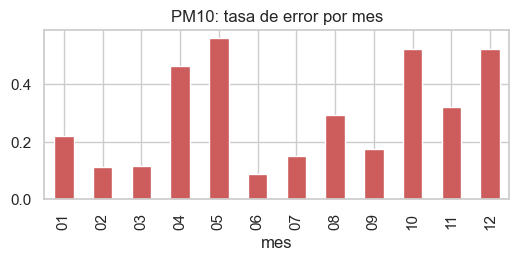

PM2.5


,tasa_error,errores,n
estacion,,,
NTE,1.000,2,2
SE3,0.500,9,18
SE2,0.400,8,20
CE,0.389,7,18
NO2,0.375,6,16


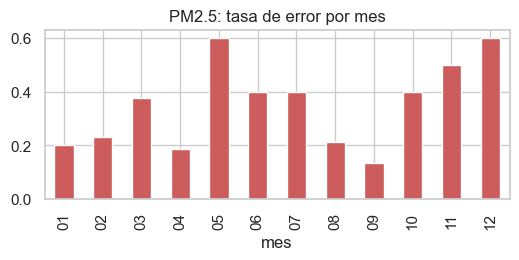

NO2


,tasa_error,errores,n
estacion,,,
NE2,0.474,9,19
SE2,0.421,8,19
NTE2,0.348,8,23
NO2,0.300,6,20
NE,0.286,2,7


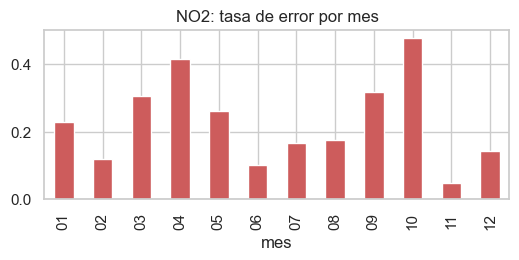

In [42]:
for c in CONTAMINANTES:
    r = cv_pred[c].assign(error=lambda t: (t.y != t.pred).astype(int), mes=lambda t: t.fecha_mes.str[-2:])
    por_est = r.groupby("estacion").error.agg(["mean", "sum", "size"]).rename(columns={"mean": "tasa_error", "sum": "errores", "size": "n"})
    por_mes = r.groupby("mes").error.mean()
    print(f"{c}")
    display(por_est.sort_values("tasa_error", ascending=False).head(5))
    por_mes.plot.bar(figsize=(6, 2.2), title=f"{c}: tasa de error por mes", color="indianred"); plt.show()

# Variables más importantes
Odds ratio por 1 DE (IC 95 %, errores agrupados por estación). La línea en 1 = sin efecto; si el intervalo cruza el 1, el efecto no es significativo.

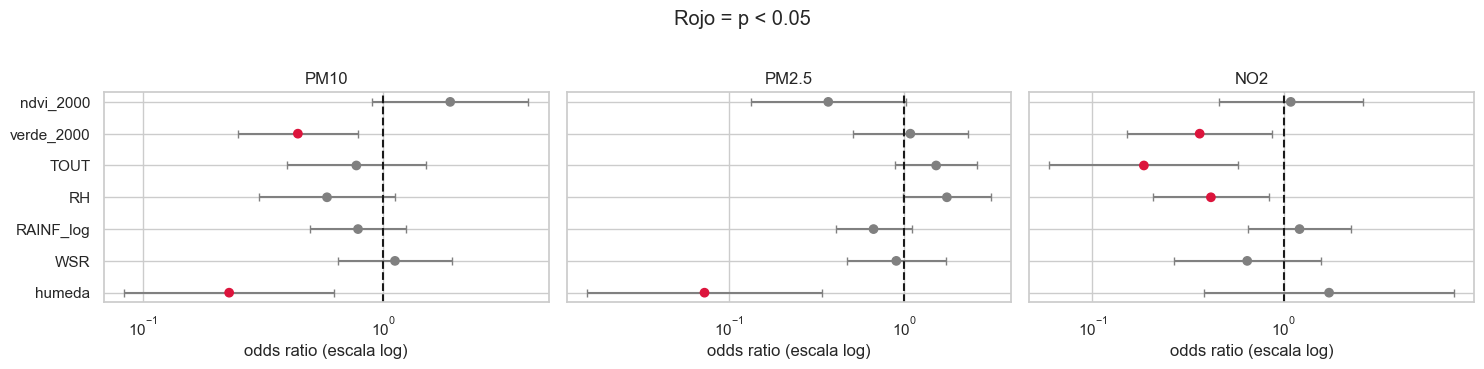

,PM10,PM2.5,NO2
|coef| estandarizado,,,
humeda,1.477,2.625,0.545
verde_2000,0.818,0.082,1.012
ndvi_2000,0.641,0.998,0.084
RH,0.539,0.562,0.877
TOUT,0.258,0.421,1.683
RAINF_log,0.242,0.402,0.189
WSR,0.112,0.103,0.440


In [43]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.6), sharey=True)
for ax, c in zip(axes, CONTAMINANTES):
    t = tablas[c].drop(index="const").iloc[::-1]
    sig = t.p < 0.05
    ax.errorbar(t.OR, range(len(t)), xerr=[t.OR - t.IC95_inf, t.IC95_sup - t.OR], fmt="none", ecolor="gray", capsize=3)
    ax.scatter(t.OR, range(len(t)), c=np.where(sig, "crimson", "gray"), zorder=3)
    ax.axvline(1, color="k", ls="--"); ax.set_xscale("log"); ax.set_title(c); ax.set_xlabel("odds ratio (escala log)")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
plt.suptitle("Rojo = p < 0.05", y=1.02); plt.tight_layout(); plt.show()

# Resumen: importancia = |coeficiente estandarizado|
imp = pd.DataFrame({c: tablas[c]["coef"].abs() for c in CONTAMINANTES}).drop(index="const")
imp.sort_values(CONTAMINANTES[0], ascending=False).rename_axis("|coef| estandarizado")